# Pruebas y Desarrollo de FotoApp (Parte 1)
En este notebook importamos nuestro módulo `fotoapp.py` para validar la carga, redimensionamiento, ecualización, filtros de Pillow y detección de bordes con OpenCV.

c:\Users\danyd\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


¡ÉXITO! Imagen descargada y adaptada. Tamaño: (1080, 1080)


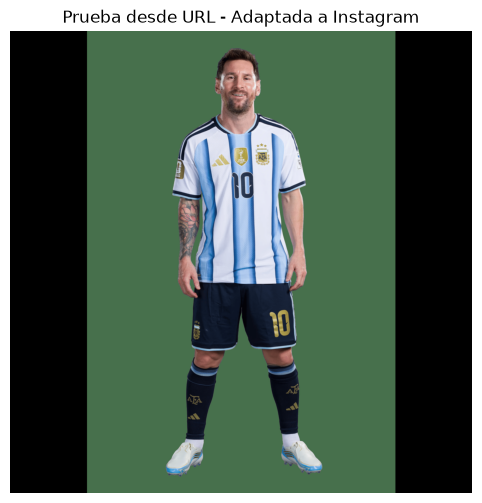

In [1]:
%matplotlib inline
import importlib
import matplotlib.pyplot as plt
import fotoapp

importlib.reload(fotoapp)

# URL estática con tamaño estándar permitido por Wikimedia (500px)
url_directa = "https://assets.footylogos.com/player-pngs/png/2940170ff06119e58f50784070d49a6728032c74c6708ae5d76275795d2af808.png"

try:
    img_red = fotoapp.cargar_y_redimensionar(url_directa, "instagram")
    print(f"¡ÉXITO! Imagen descargada y adaptada. Tamaño: {img_red.size}")
    
    plt.figure(figsize=(6, 6))
    plt.imshow(img_red)
    plt.title("Prueba desde URL - Adaptada a Instagram")
    plt.axis("off")
    plt.show()

except Exception as e:
    print(f"Error detectado: {e}")

Tamaño adaptado Instagram: (1080, 1080)
Tamaño adaptado YouTube: (1280, 720)


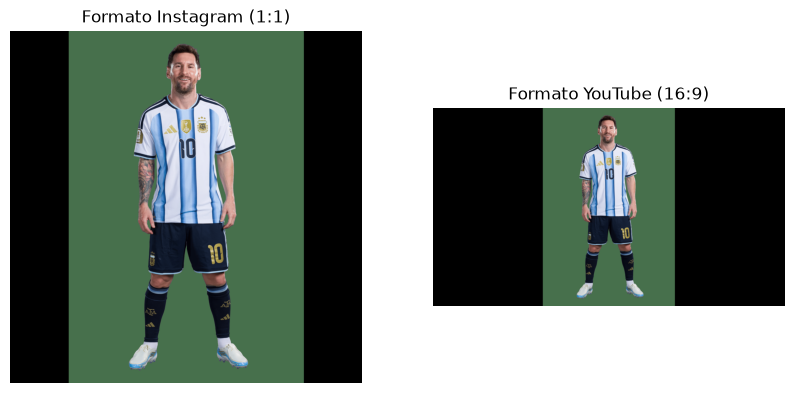

In [19]:
url_messi = "https://assets.footylogos.com/player-pngs/png/2940170ff06119e58f50784070d49a6728032c74c6708ae5d76275795d2af808.png"

# Probamos adaptarlo a formato YouTube (1280x720) e Instagram (1080x1080)
img_messi_ig = fotoapp.cargar_y_redimensionar(url_messi, "instagram").convert("RGB")
img_messi_yt = fotoapp.cargar_y_redimensionar(url_messi, "youtube").convert("RGB")

print(f"Tamaño adaptado Instagram: {img_messi_ig.size}")
print(f"Tamaño adaptado YouTube: {img_messi_yt.size}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_messi_ig)
axes[0].set_title("Formato Instagram (1:1)")
axes[0].axis("off")

axes[1].imshow(img_messi_yt)
axes[1].set_title("Formato YouTube (16:9)")
axes[1].axis("off")
plt.show()

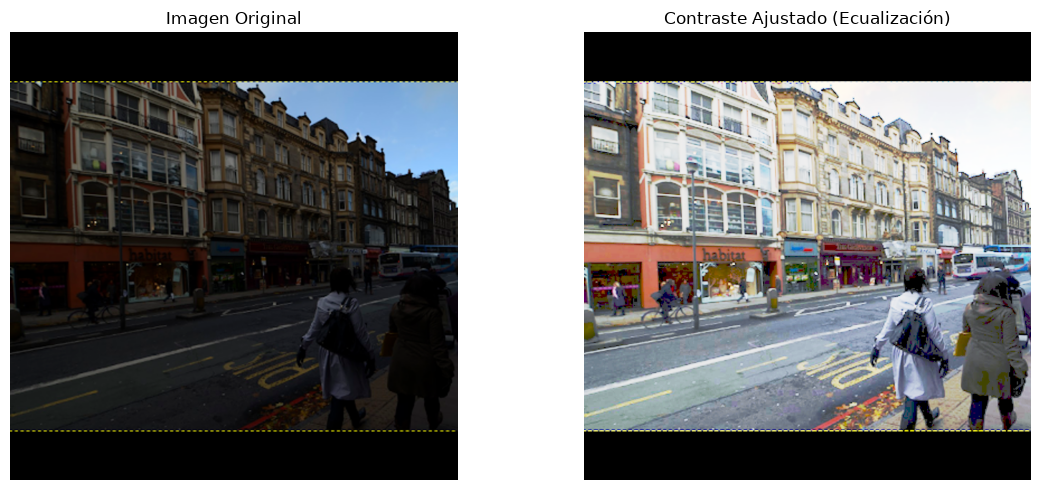

In [21]:
# Usamos una foto oscura/subexpuesta (puedes cambiarla por otra local si tienes en imagenes/)
url_oscura = "./imagenes/oscur.png"

img_oscura = fotoapp.cargar_y_redimensionar(url_oscura, "instagram").convert("RGB")
img_ecualizada = fotoapp.ajustar_contraste_histograma(img_oscura, "contraste_noche_estrellada.png")

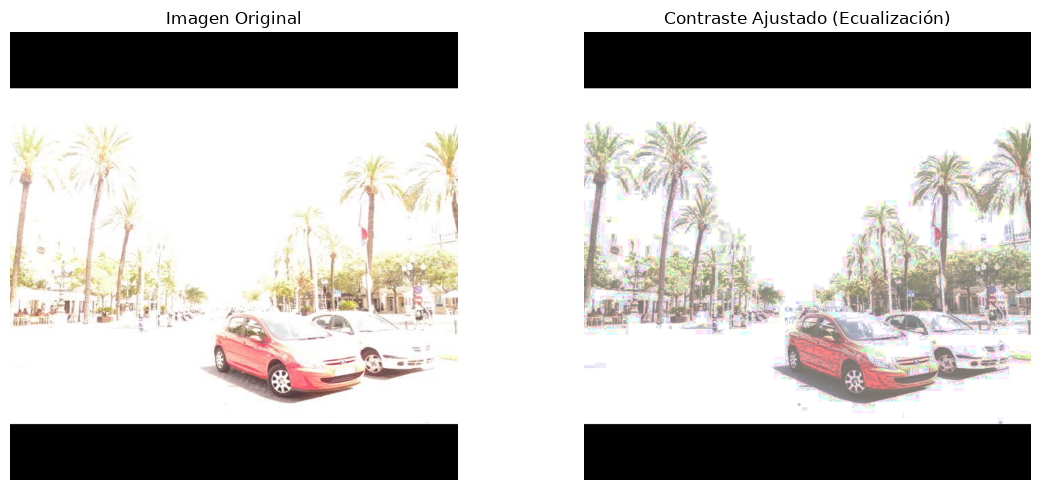

In [22]:
# Foto muy iluminada
ruta_clara = "imagenes/ilumi.jpg"

img_clara = fotoapp.cargar_y_redimensionar(ruta_clara, "instagram").convert("RGB")
img_ecualizada_clara = fotoapp.ajustar_contraste_histograma(img_clara, "contraste_clara.png")

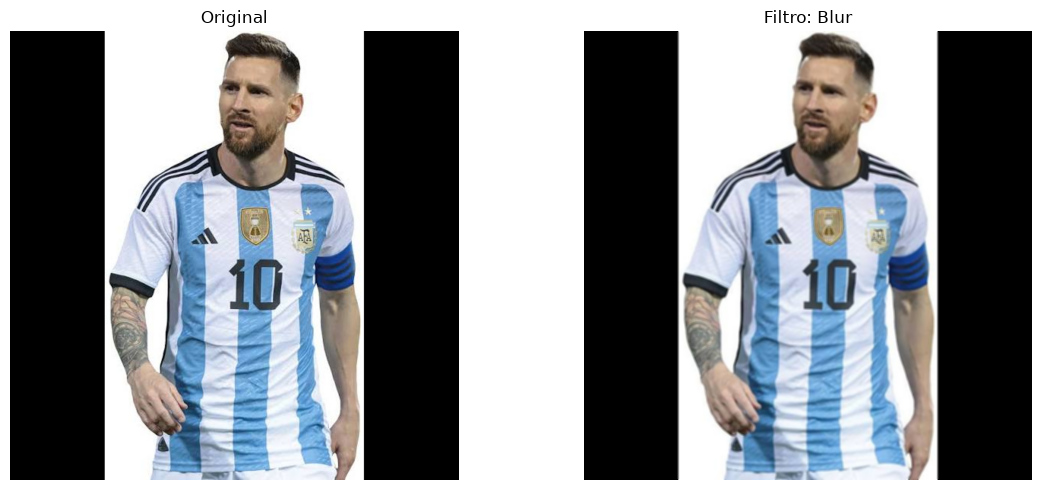

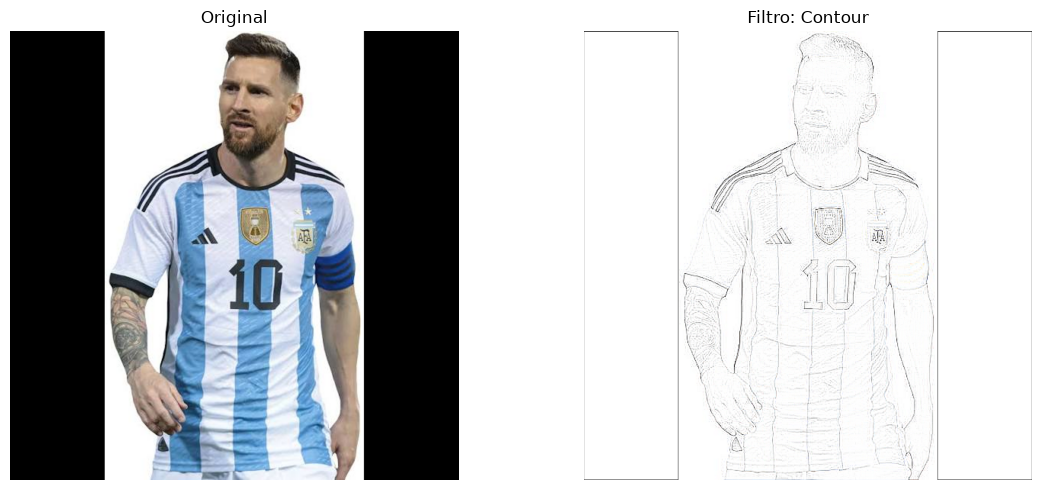

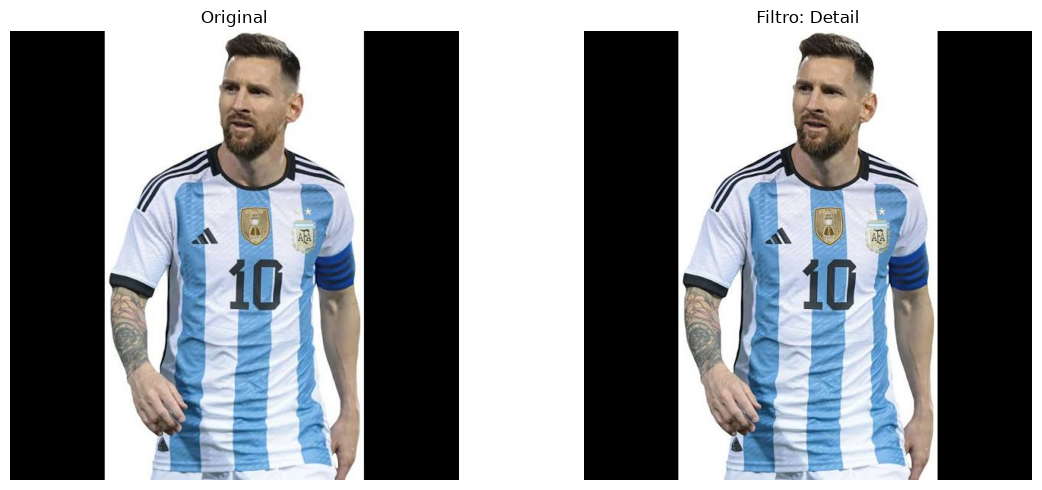

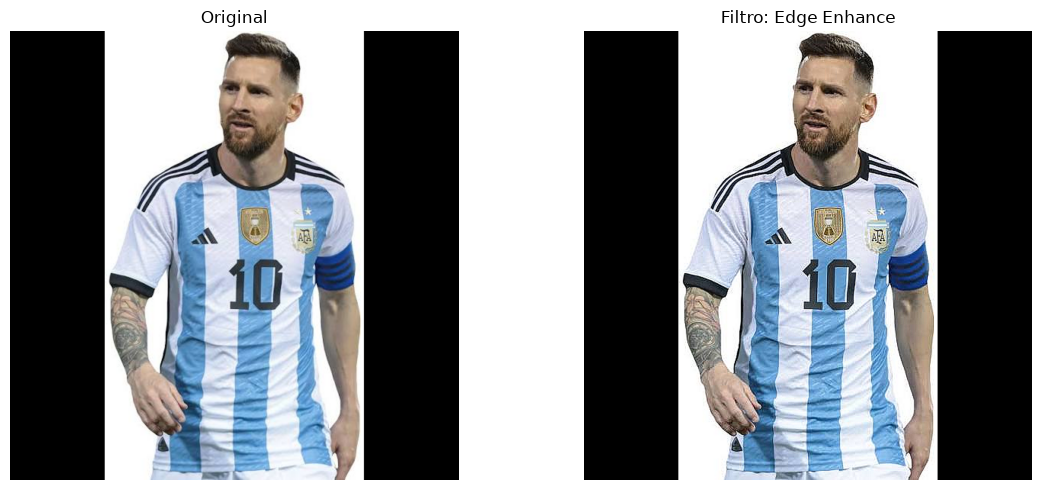

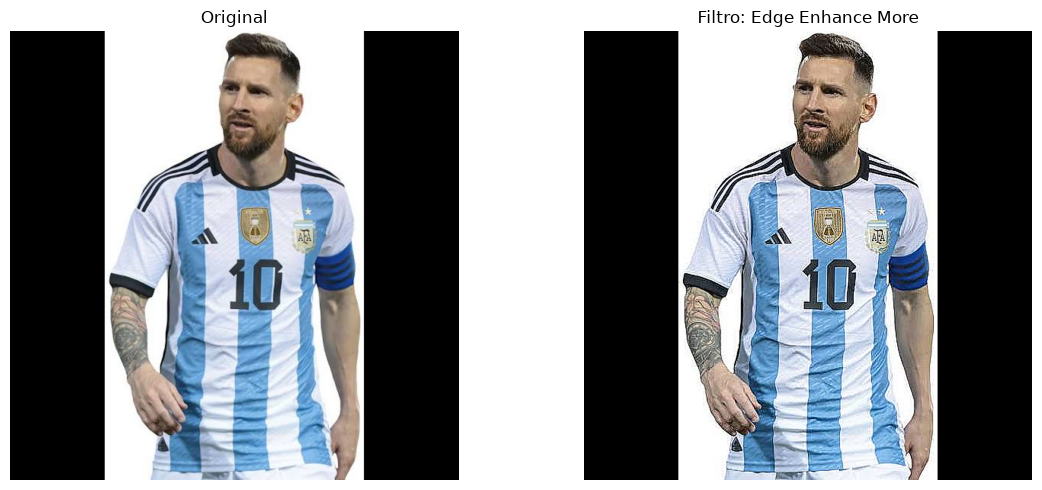

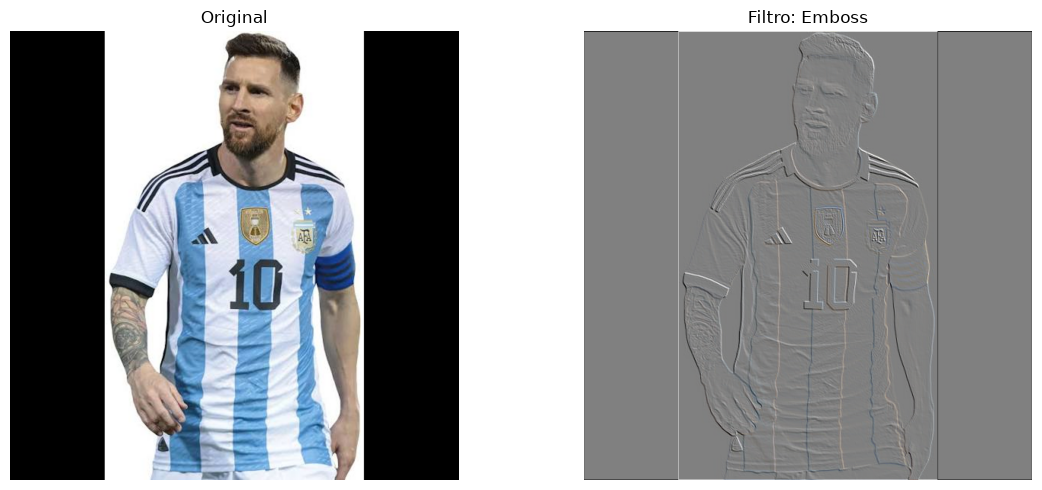

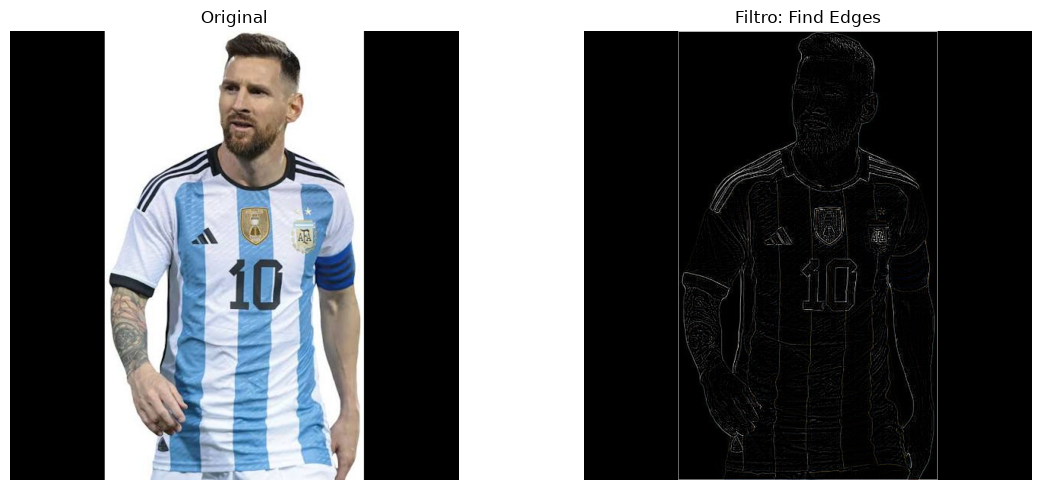

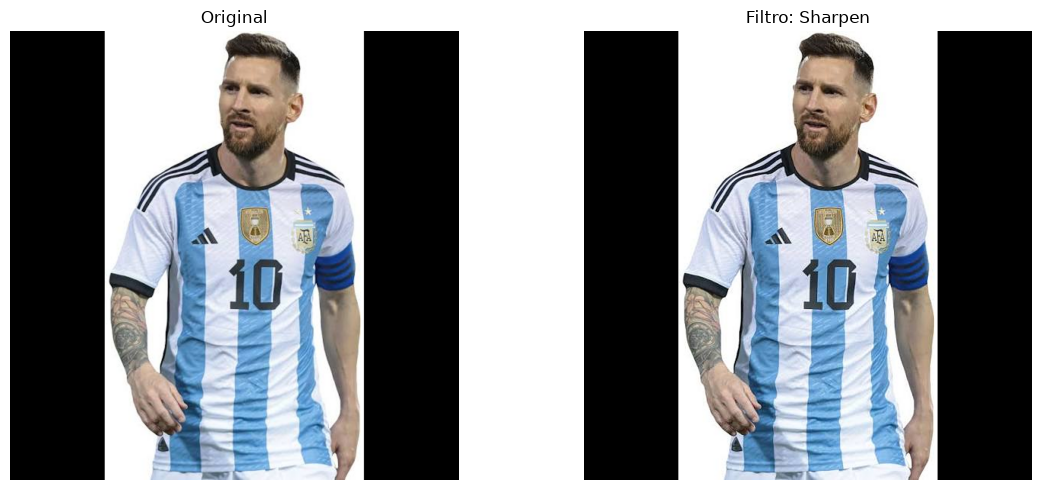

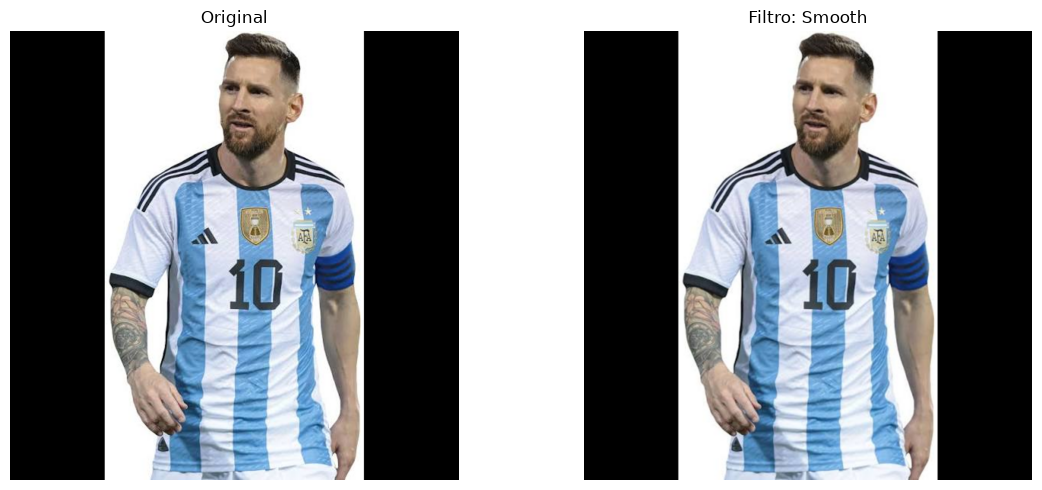

In [29]:
# Probamos la Función 3: Aplicar un filtro específico de Pillow
# imag con detalles arquitectónicos o naturales
url_detalle = "./imagenes/mesi.jpg"
img_detalle = fotoapp.cargar_y_redimensionar(url_detalle, "instagram").convert("RGB")

# Aplicamos los 9 filtros del 1 al 9
for num_filtro in range(1, 10):
    fotoapp.aplicar_filtro_pillow(img_detalle, num_filtro)

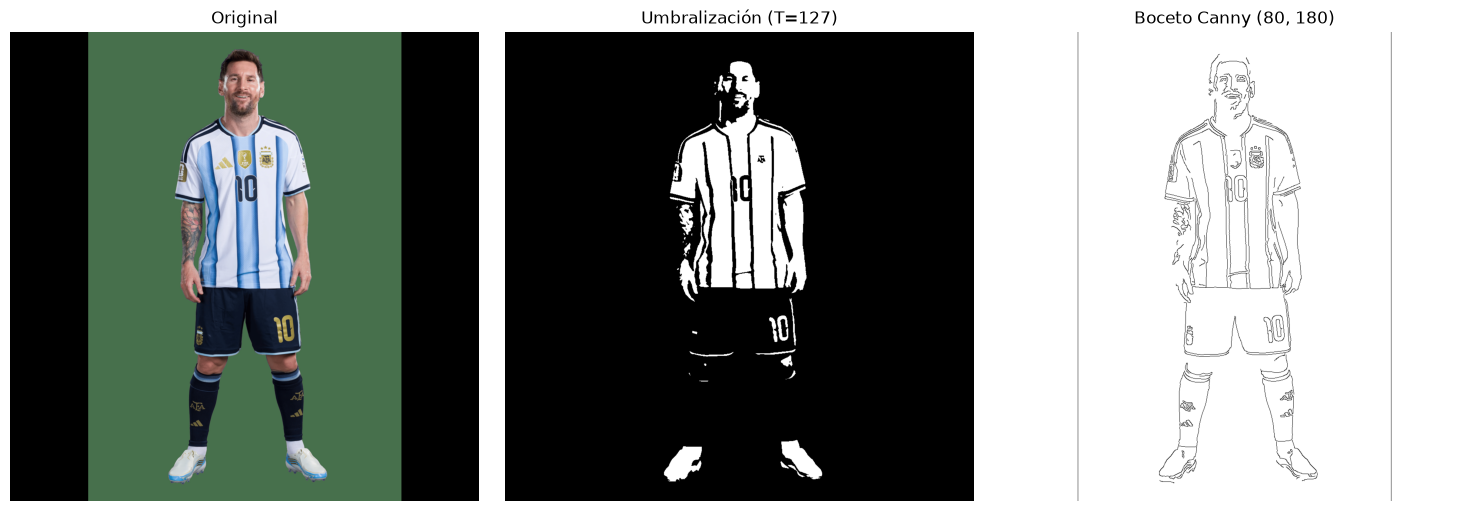

In [ ]:
# Función 4: Umbralización vs Canny (Boceto)
# función de bordes sobre la imagen de Messi
borde_umbral, borde_canny = fotoapp.generar_boceto_bordes(
    img_messi_ig,
    umbral_binario=127,
    canny_min=80,
    canny_max=180,
    nombre_salida="boceto_messi_hd.png"
)